# `ivg` usage example

Implementation of the **Image Visibility Graph** of Iacovacci & Lacasa (2019), with both criteria:

| `criterion` | graph | patches |
|---|---|---|
| `"natural"` | IVG | VP$_p$ — order-3 motif: $x_2 > 2x_1 - x_0$ |
| `"horizontal"` | IHVG | HVP$_p$ — order-3 motif: $x_1 < \min(x_0, x_2)$ |

This notebook uses synthetic images so it runs without external data. To use your own image: `img = ivg.load_gray("path/to/image.png")`.

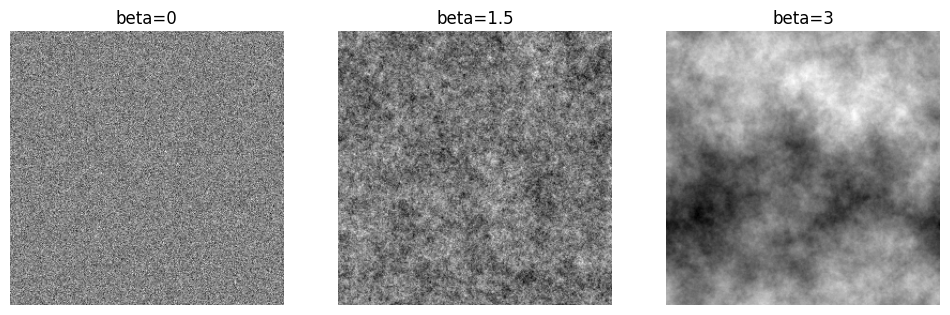

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ivg

rng = np.random.default_rng(0)

def correlated_surface(n, beta, rng):
    """Random surface with power spectrum ~ 1/|f|^beta (beta=0: white noise)."""
    fx = np.fft.fftfreq(n)[:, None]
    fy = np.fft.fftfreq(n)[None, :]
    f = np.hypot(fx, fy); f[0, 0] = 1.0
    spec = (rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n))) / f ** (beta / 2)
    z = np.real(np.fft.ifft2(spec))
    return (255 * (z - z.min()) / (z.max() - z.min())).astype(np.uint8)

images = {f"beta={b}": correlated_surface(256, b, rng) for b in (0, 1.5, 3)}
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (name, im) in zip(ax, images.items()):
    a.imshow(im, cmap="gray"); a.set_title(name); a.axis("off")

## 1. Local features: Visibility Patch profile $\mathbf{Z}$

For $p=3$ there are $2^8=256$ labels; `to_dense()` returns $Z=(Z_1,\dots,Z_{256})$ (position `l-1` holds label `l`).

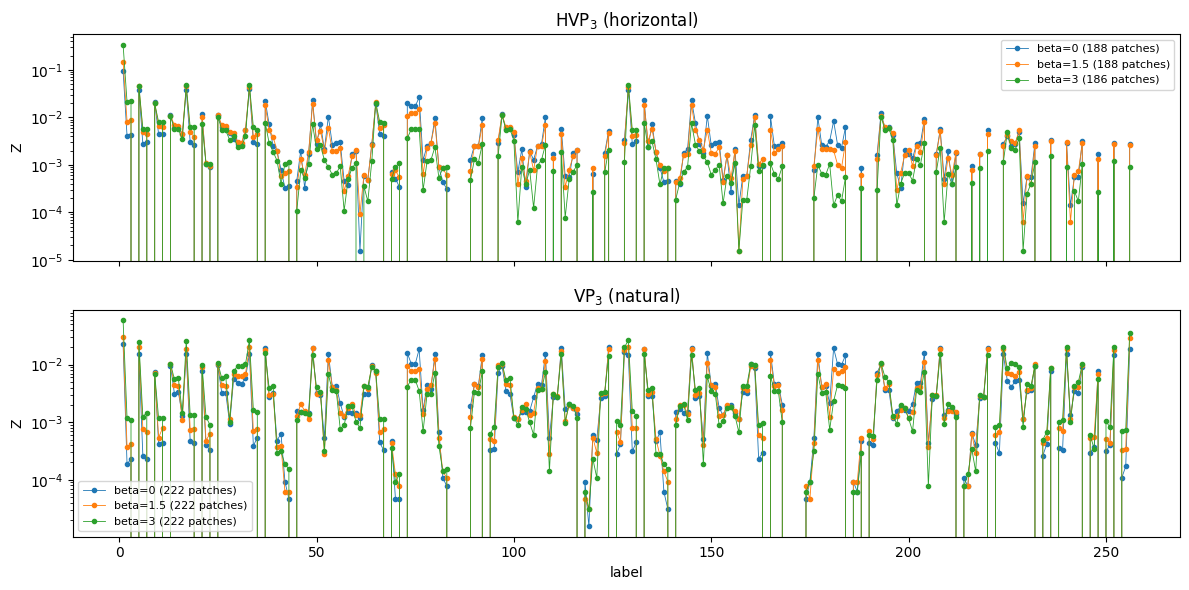

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for name, im in images.items():
    for a, crit in zip(ax, ("horizontal", "natural")):
        prof = ivg.patch_profile(im, order=3, criterion=crit)
        a.plot(np.arange(1, 257), prof.to_dense(normalize=True), ".-", lw=0.6, label=f"{name} ({len(prof)} patches)")
for a, t in zip(ax, ("HVP$_3$ (horizontal)", "VP$_3$ (natural)")):
    a.set_yscale("log"); a.set_ylabel("Z"); a.set_title(t); a.legend(fontsize=8)
ax[1].set_xlabel("label")
plt.tight_layout()

Interpreting a label: which rows/columns/diagonals carry motif 1 (the example of Fig. 4 in the paper).

In [3]:
ivg.decode_label(135, order=3)

{'r1': 1,
 'r2': 0,
 'r3': 0,
 'c1': 0,
 'c2': 0,
 'c3': 1,
 'd1': 1,
 'd2': 0,
 'd1+1': 0,
 'd1-1': 0,
 'd2+1': 0,
 'd2-1': 0}

Per-patch label map (where each pattern occurs):

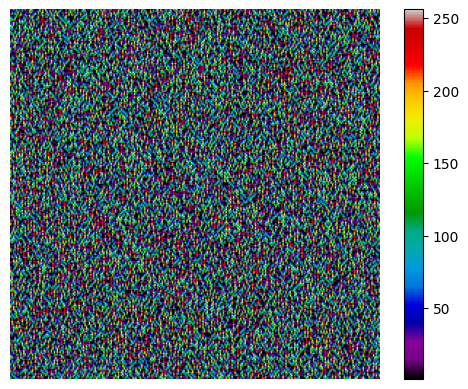

In [4]:
Lmap = ivg.patch_label_map(images["beta=1.5"], order=3, criterion="horizontal")
plt.imshow(Lmap, cmap="nipy_spectral"); plt.colorbar(); plt.axis("off");

### Higher orders ($p \ge 4$)

For $p\ge4$ each line has more than 2 possible motifs and the $4(p-2)$ off-diagonals are added,
so the label space is huge ($2^{34}$ for $p=4$). The profile is stored **sparsely**.
To compare several images use `profile_matrix`, which aligns the columns.

In [5]:
prof4 = ivg.patch_profile(images["beta=3"], order=4, criterion="horizontal")
print(len(prof4), "distinct labels in", prof4.n_patches, "patches")
prof4.most_common(5)

35939 distinct labels in 64009 patches


[(1, 3156), (2147483649, 445), (16777217, 428), (4194305, 423), (524289, 408)]

In [6]:
profs = [ivg.patch_profile(im, order=3, criterion="horizontal") for im in images.values()]
X, labels = ivg.profile_matrix(profs, normalize=True)   # (n_images, n_labels) feature matrix
X.shape

(3, 188)

## 2. Global features: full graph and $P(k)$

Nodes = pixels; edges along rows, columns, diagonals and anti-diagonals.

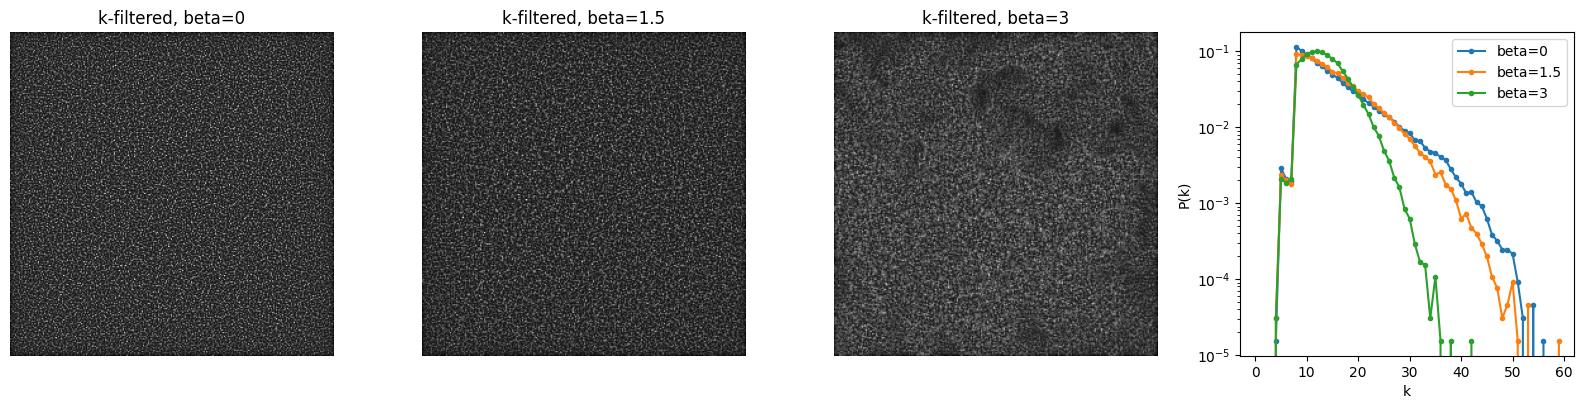

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i, (name, im) in enumerate(images.items()):
    G = ivg.image_visibility_graph(im, criterion="horizontal")
    ax[i].imshow(G.degree_map(), cmap="gray"); ax[i].set_title(f"k-filtered, {name}"); ax[i].axis("off")
    Pk = G.degree_distribution()
    ax[3].semilogy(np.arange(len(Pk)), Pk, ".-", label=name)
ax[3].set_xlabel("k"); ax[3].set_ylabel("P(k)"); ax[3].legend()
plt.tight_layout()

## 3. A real image: the solar photosphere (SDO/HMI)

Full-disk continuum intensitygram from the Helioseismic and Magnetic Imager.
*Courtesy of NASA/SDO and the AIA, EVE, and HMI science teams.*

The black background outside the disk is constant (all ties), so we analyse two crops **inside** the disk:
an active region containing sunspots and a quiet-Sun region at disk centre.

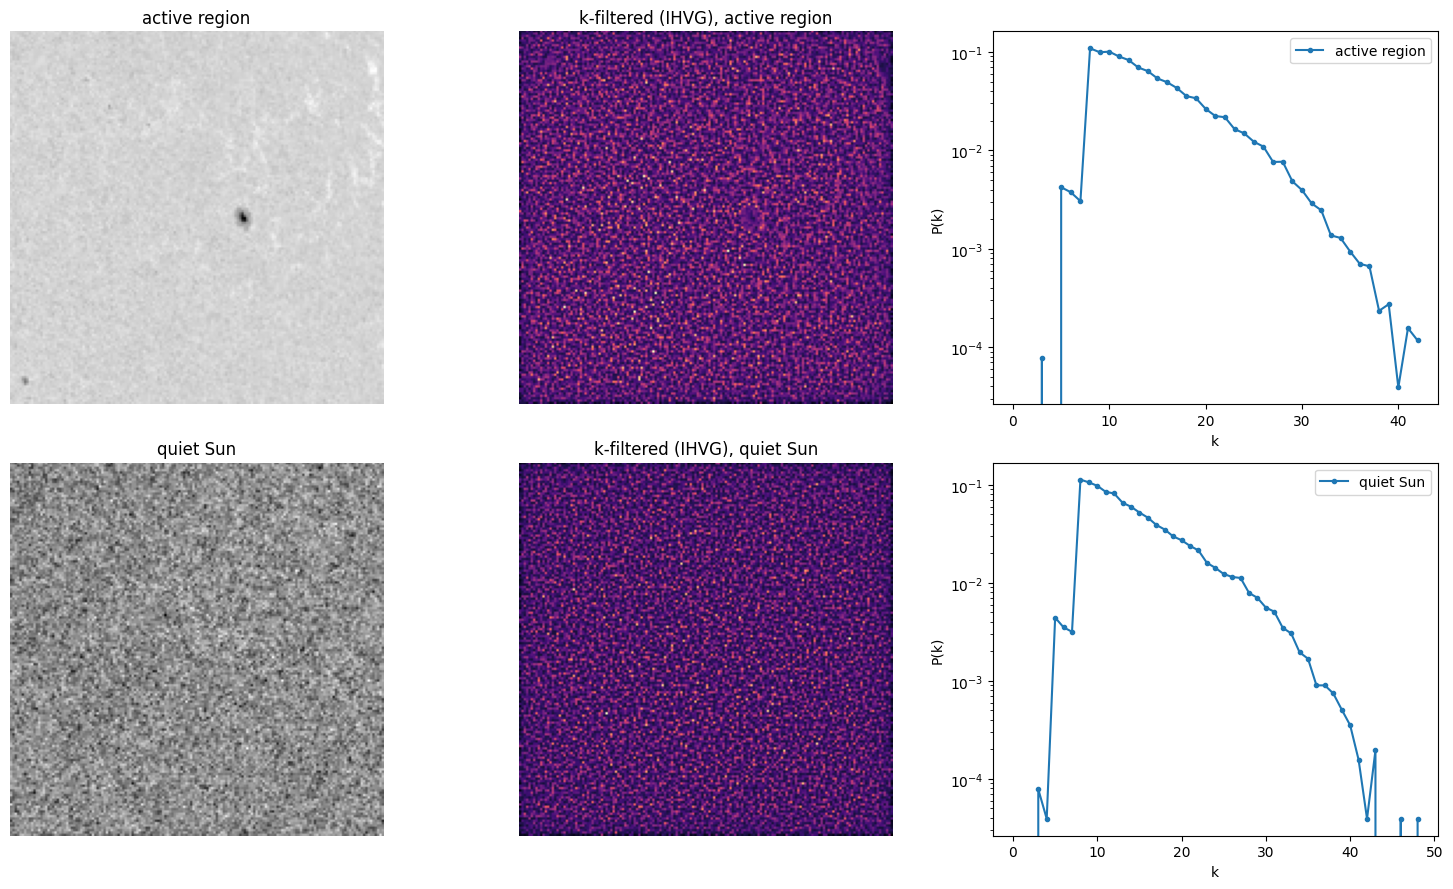

In [8]:
sun = ivg.load_gray("data/sdo_hmi_intensitygram_1024.jpg")
crops = {
    "active region": sun[311:471, 752:912],   # contains a sunspot group
    "quiet Sun":     sun[432:592, 432:592],   # disk centre
}

fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for row, (name, im) in enumerate(crops.items()):
    G = ivg.image_visibility_graph(im, criterion="horizontal")
    ax[row, 0].imshow(im, cmap="gray"); ax[row, 0].set_title(name); ax[row, 0].axis("off")
    ax[row, 1].imshow(G.degree_map(), cmap="magma"); ax[row, 1].set_title(f"k-filtered (IHVG), {name}"); ax[row, 1].axis("off")
    Pk = G.degree_distribution()
    ax[row, 2].semilogy(np.arange(len(Pk)), Pk, ".-", label=name)
    ax[row, 2].set_xlabel("k"); ax[row, 2].set_ylabel("P(k)"); ax[row, 2].legend()
plt.tight_layout()

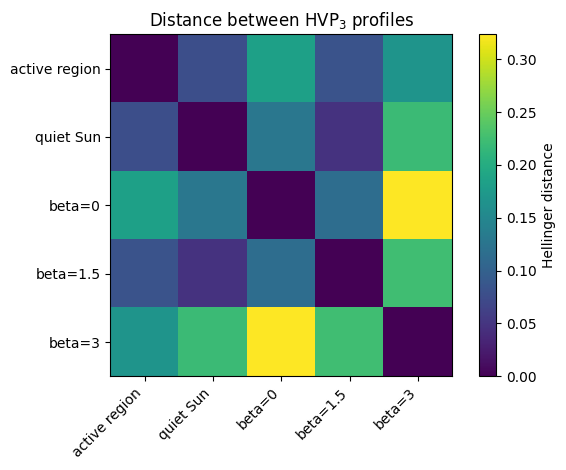

In [9]:
profs_sun = [ivg.patch_profile(im, 3, "horizontal") for im in crops.values()]
profs_syn = [ivg.patch_profile(im, 3, "horizontal") for im in images.values()]
X, labels = ivg.profile_matrix(profs_sun + profs_syn)
names = list(crops) + list(images)

# Hellinger distance between HVP3 profiles
H = np.sqrt(0.5 * ((np.sqrt(X[:, None, :]) - np.sqrt(X[None, :, :])) ** 2).sum(-1))
plt.imshow(H, cmap="viridis"); plt.colorbar(label="Hellinger distance")
plt.xticks(range(len(names)), names, rotation=45, ha="right"); plt.yticks(range(len(names)), names)
plt.title("Distance between HVP$_3$ profiles"); plt.tight_layout()

For fixed-length vectors across images use `G.degree_distribution(kmax=...)`. `G.to_networkx()` or `G.adjacency()` enable any further analysis.